# ISO 20414:2020 — Test 11: Maximum flow rates at an opening/exit

100 occupants in an 8 m x 5 m room with a 1 m exit centred on the 5 m wall (ISO 20414:2020 Table 12). The criterion is that the exit flow does not exceed the predefined maximum of 1.33 p/m/s (IMO MSC/Circ.1238 reference). The CollisionFreeSpeedModel has no door-flow limit of its own, so the verification runs with the jupedsim-scenarios exit throughput limiter enabled at 1.33 p/s and checks that the measured flow stays at or below it. The emergent flow without the limiter is shown for comparison.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 10:39 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

## Load and run

In [4]:
SCENARIO_ZIP = Path("scenario_files") / "Iso-11-max-flow.zip"
CAP_PMS = 1.33  # p/m/s; equals the limiter's max_throughput (p/s) for a 1 m exit
EXIT_WIDTH_M = 1.0
CAP_TOLERANCE = 0.01  # relative; see the acceptance cell


def run(limiter_on):
    scenario = load_scenario(str(SCENARIO_ZIP))
    for exit_ in scenario.raw["exits"].values():
        exit_["enable_throughput_throttling"] = limiter_on
        exit_["max_throughput"] = CAP_PMS
    result = run_scenario(scenario, seed=42)
    return scenario, result, result.trajectory_dataframe()


runs = {"limiter off": run(False), "limiter on": run(True)}
scenario, result, df = runs["limiter on"]
print(scenario.summary())

Scenario: scenario_files/Iso-11-max-flow.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      240s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~100
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 100 agents


## Scenario check — geometry and trajectories

Confirm the simulated layout: an 8 m x 5 m room with a 1 m exit centred on the 5 m (left) wall; 100 occupants converge on the exit.

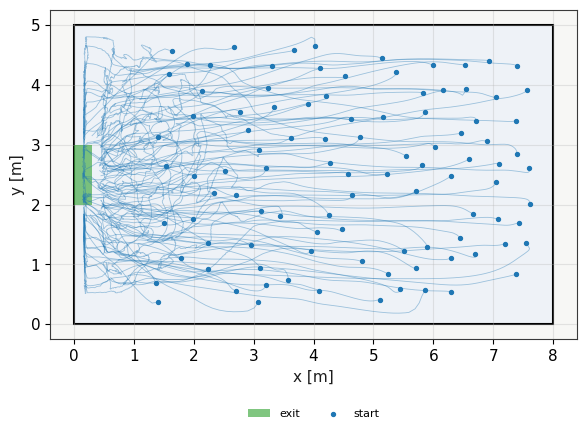

In [5]:
scen = scenario
tdf = df
poly = scen.walkable_polygon
fig, ax = plt.subplots(figsize=(6, 4.5))
gx, gy = poly.exterior.xy
ax.fill(gx, gy, facecolor='#eef2f7', edgecolor='k', lw=1.5, zorder=0)
for interior in poly.interiors:
    ix, iy = interior.xy
    ax.fill(ix, iy, facecolor='white', edgecolor='k', lw=1.0, zorder=1)
for z in scen.zones.values():
    zx = [c[0] for c in z['coordinates']]
    zy = [c[1] for c in z['coordinates']]
    ax.fill(zx, zy, facecolor='tab:orange', alpha=0.18, edgecolor='tab:orange',
            zorder=1, label=f"speed-factor {z.get('speed_factor')} zone")
for e in scen.exits.values():
    ex = [c[0] for c in e['coordinates']]
    ey = [c[1] for c in e['coordinates']]
    ax.fill(ex, ey, facecolor='tab:green', alpha=0.6, zorder=2, label='exit')
for _, sub in tdf.sort_values(['id', 'frame']).groupby('id'):
    ax.plot(sub.x, sub.y, color='tab:blue', lw=0.6, alpha=0.4, zorder=3)
starts = tdf.sort_values(['id', 'frame']).groupby('id').first()
ax.scatter(starts.x, starts.y, s=8, color='tab:blue', zorder=4, label='start')
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), fontsize=8, loc='upper center',
          bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
plt.tight_layout(); plt.show()


## Exit times and specific flow

An agent is removed when the exit stage accepts it, and the limiter delays that removal while the agent waits inside the exit polygon. The exit time is therefore the agent's last trajectory frame, not its first crossing of the exit line.

Specific flow = (N - 1) / (t_last - t_first) / exit width, over the N exit times (N - 1 intervals).

In [6]:
exit_times = {}
for name, (_, res, tdf_) in runs.items():
    exit_times[name] = np.sort((tdf_.groupby("id").frame.max() / res.frame_rate).values)


def specific_flow(times):
    return (len(times) - 1) / (times[-1] - times[0]) / EXIT_WIDTH_M


flows = {name: specific_flow(t) for name, t in exit_times.items()}
for name, t in exit_times.items():
    print(f"{name:12s}: N = {len(t)}, first exit {t[0]:.1f} s, last exit {t[-1]:.1f} s, "
          f"specific flow = {flows[name]:.3f} p/m/s")

limiter off : N = 100, first exit 0.7 s, last exit 19.6 s, specific flow = 5.238 p/m/s
limiter on  : N = 100, first exit 0.7 s, last exit 76.0 s, specific flow = 1.315 p/m/s


## Cumulative exits

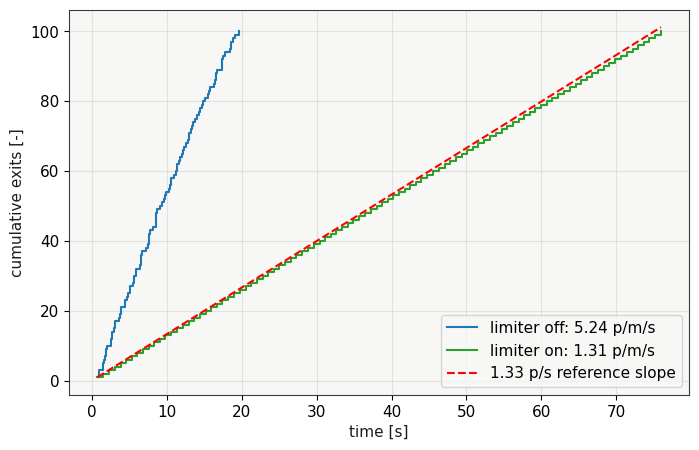

In [7]:
fig, ax = plt.subplots()
colors = {"limiter off": "tab:blue", "limiter on": "tab:green"}
for name, t in exit_times.items():
    ax.step(t, np.arange(1, len(t) + 1), where="post", color=colors[name],
            label=f"{name}: {flows[name]:.2f} p/m/s")
t_on = exit_times["limiter on"]
ref_t = np.array([t_on[0], t_on[-1]])
ax.plot(ref_t, 1 + CAP_PMS * EXIT_WIDTH_M * (ref_t - t_on[0]), "r--",
        label=f"{CAP_PMS} p/s reference slope")
ax.set_xlabel("time [s]"); ax.set_ylabel("cumulative exits [-]"); ax.legend()
plt.show()

## Acceptance (restricted-flow reading, maintainer decision D12)

ISO 20414 Test 11 requires that the exit flow does not exceed the predefined maximum of 1.33 p/m/s (1.33 p/s for this 1 m exit). The run enables the jupedsim-scenarios exit throughput limiter (`enable_throughput_throttling = True`, `max_throughput = 1.33` p/s) and asserts that the measured specific flow stays at or below the cap, with a relative tolerance of 1 %. The tolerance covers the 0.1 s sampling of the trajectory file against an egress span of about 75 s (under 0.3 %); the limiter's tick discretisation only lowers the flow.

The emergent flow with the limiter off is reported for information only and is not asserted.

In [8]:
cap = CAP_PMS * (1 + CAP_TOLERANCE)
print(f"limiter on : {flows['limiter on']:.3f} p/m/s (cap {CAP_PMS}, with tolerance {cap:.4f})")
print(f"limiter off: {flows['limiter off']:.3f} p/m/s (emergent, information only)")
for name, (_, res, _) in runs.items():
    print(f"{name}: evacuation time = {res.evacuation_time:.1f} s; agents remaining = {res.agents_remaining}")
    assert res.agents_remaining == 0, (name, res.agents_remaining)
assert flows["limiter on"] <= cap, flows["limiter on"]
for _, res, _ in runs.values():
    res.cleanup()

limiter on : 1.315 p/m/s (cap 1.33, with tolerance 1.3433)
limiter off: 5.238 p/m/s (emergent, information only)
limiter off: evacuation time = 19.7 s; agents remaining = 0
limiter on: evacuation time = 76.0 s; agents remaining = 0
